<a href="https://colab.research.google.com/github/tasosquantumcomputing/Sign-Mnist-Classification/blob/main/ergasia_1_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **[A]. Data Exploration & Preprocessing**

---



## **Libraries Import**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [ ]:
df = pd.read_csv("sign_mnist_train.csv")

# **Dataset informations**

---



In [ ]:
print(f"Συνολικές γραμμές : {len(df)}")
print(f"Στήλες            : {df.shape[1]}")
print(f"Κλάσεις           : {df['label'].nunique()}")
display(df.head())

Συνολικές γραμμές : 27455
Στήλες            : 785
Κλάσεις           : 24


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [ ]:
px = df.drop('label', axis=1)
print(f"  Min  : {px.values.min()}")
print(f"  Max  : {px.values.max()}")
print(f"  Mean : {px.values.mean():.2f}")
print(f"  Std  : {px.values.std():.2f}")

  Min  : 0
  Max  : 255
  Mean : 159.29
  Std  : 48.77


In [ ]:
print(f"  Labels στο dataset: {sorted(df['label'].unique())}")
print(f"  Min δείγματα ανά κλάση: {df['label'].value_counts().min()}")
print(f"  Max δείγματα ανά κλάση: {df['label'].value_counts().max()}")

  Labels στο dataset: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
  Min δείγματα ανά κλάση: 957
  Max δείγματα ανά κλάση: 1294


In [ ]:
LABEL_TO_LETTER = {
    0:'A', 1:'B', 2:'C', 3:'D', 4:'E', 5:'F', 6:'G', 7:'H', 8:'I',
    # 9 = J (δεν υπάρχει)
    10:'K', 11:'L', 12:'M', 13:'N', 14:'O', 15:'P', 16:'Q', 17:'R',
    18:'S', 19:'T', 20:'U', 21:'V', 22:'W', 23:'X', 24:'Y'
    # 25 = Z (δεν υπάρχει)
}

print(f"Labels : {sorted(df['label'].unique())}")
print(f"Γράμματα: {[LABEL_TO_LETTER[l] for l in sorted(df['label'].unique())]}")

Labels : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Γράμματα: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


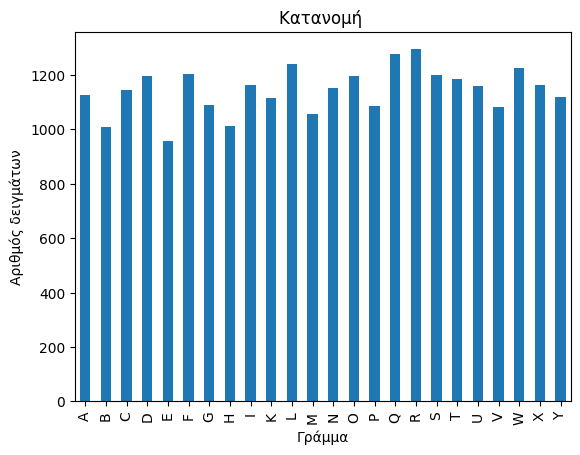

In [ ]:
counts = df['label'].value_counts().sort_index().rename(index=LABEL_TO_LETTER)
plt.figure()
counts.plot(kind='bar')
plt.title("Κατανομή ")
plt.xlabel("Γράμμα")
plt.ylabel("Αριθμός δειγμάτων")
plt.show()

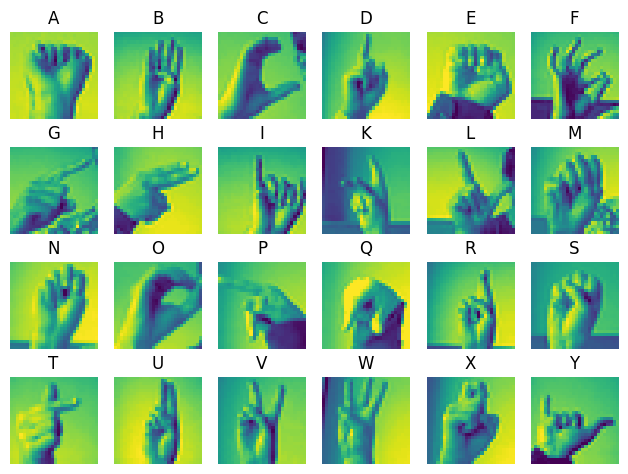

In [ ]:
for i, lbl in enumerate(sorted(df['label'].unique())):
    img = df[df['label'] == lbl].iloc[0].drop('label').values.reshape(28, 28)
    plt.subplot(4, 6, i + 1)
    plt.imshow(img)
    plt.title(LABEL_TO_LETTER[lbl])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
X = df.drop('label', axis=1).values.astype(np.float32) / 255.0
y = df['label'].values

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.20)

# **[Β.] Classification Models**

**k - Nearest Neighbors (kNN)**

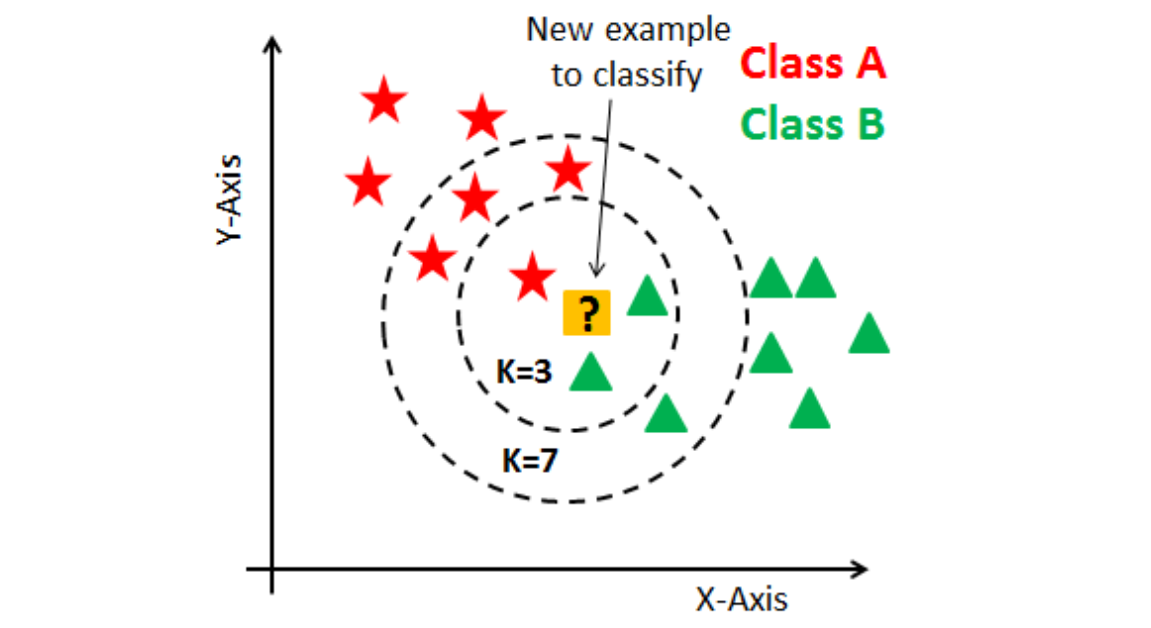

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import time

In [ ]:
k_values = [1, 3, 5, 7, 11]
metrics = ['euclidean', 'manhattan', 'cosine']

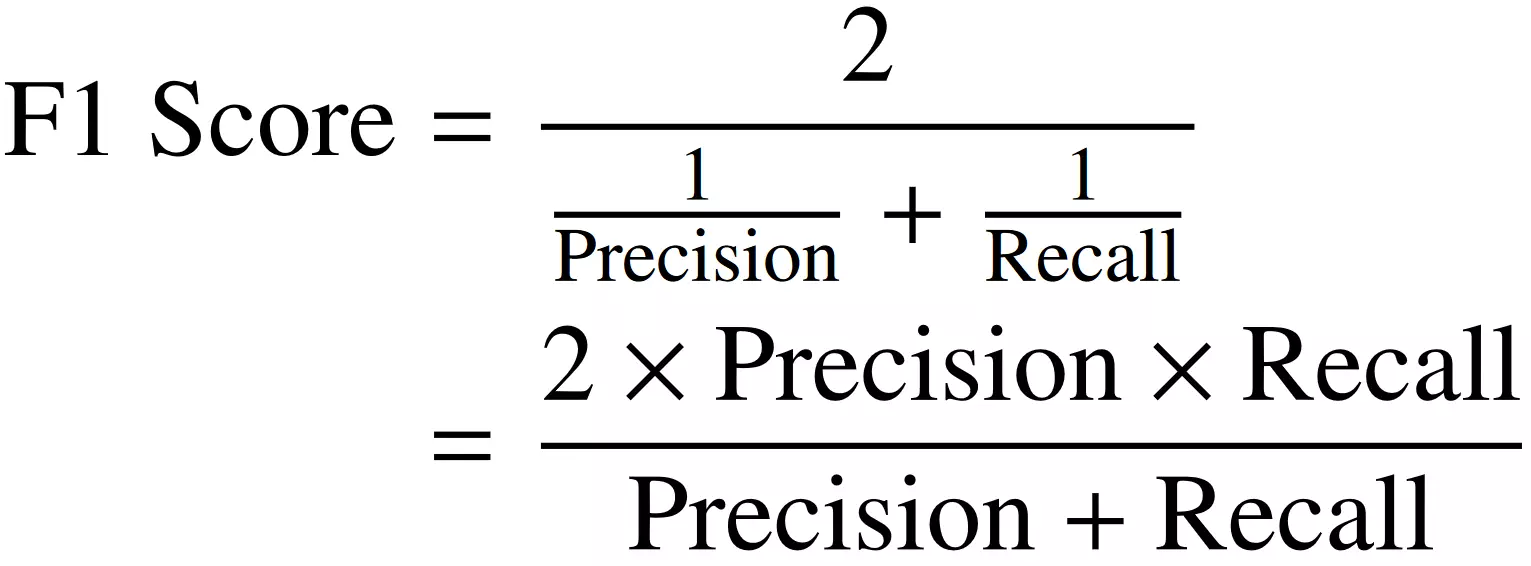

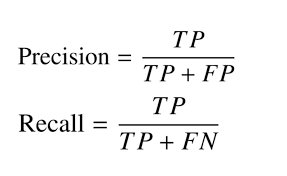

In [ ]:
knn_results = []

In [ ]:
X_tr = np.nan_to_num(X_tr)
X_val = np.nan_to_num(X_val)

for metric in metrics:
    for k in k_values:
        start = time.time()
        clf = KNeighborsClassifier(n_neighbors=k, metric=metric)
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_val)
        acc = accuracy_score(y_val, y_pred)
        f1 = f1_score(y_val, y_pred, average='weighted')
        t = time.time() - start

        result = {}
        result['k'] = k
        result['metric'] = metric
        result['accuracy'] = acc
        result['f1_score'] = f1
        result['time'] = t
        knn_results.append(result)

        print("k =", k, "metric =", metric, "Acc =", acc, "F1 =", f1, "Time =", t, "s")

df_knn = pd.DataFrame(knn_results)

k = 1 metric = euclidean Acc = 0.9996357676197414 F1 = 0.9996357267052837 Time = 11.911619901657104 s
k = 3 metric = euclidean Acc = 0.9989073028592241 F1 = 0.998906282494592 Time = 7.15254807472229 s
k = 5 metric = euclidean Acc = 0.9967219085776725 F1 = 0.9967203090974672 Time = 8.442557096481323 s
k = 7 metric = euclidean Acc = 0.9949007466763795 F1 = 0.9948923730290645 Time = 7.200054168701172 s
k = 11 metric = euclidean Acc = 0.9905299581132763 F1 = 0.9905153738226123 Time = 8.460886001586914 s
k = 1 metric = manhattan Acc = 0.9974503733381898 F1 = 0.9974533453540022 Time = 149.42148399353027 s
k = 3 metric = manhattan Acc = 0.9928974685849572 F1 = 0.9929009770830457 Time = 148.47246313095093 s
k = 5 metric = manhattan Acc = 0.9848843562192678 F1 = 0.984886844136401 Time = 148.37441730499268 s
k = 7 metric = manhattan Acc = 0.9828810781278455 F1 = 0.9828927855363191 Time = 152.44699716567993 s
k = 11 metric = manhattan Acc = 0.9628482972136223 F1 = 0.962920058264099 Time = 148.456

In [ ]:
best_knn = df_knn.loc[df_knn['accuracy'].idxmax()]

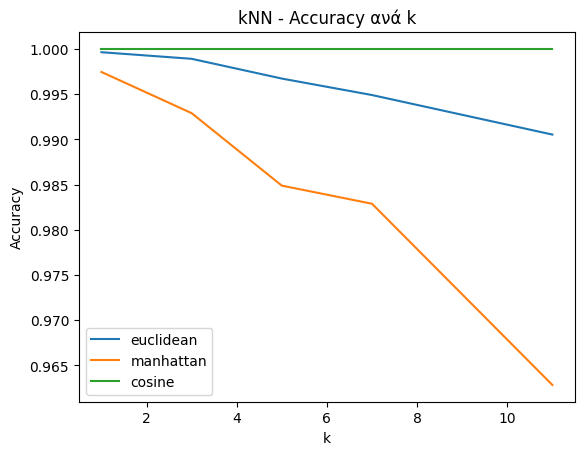

In [ ]:
for metric in metrics:
    sub = df_knn[df_knn['metric'] == metric]
    plt.plot(sub['k'], sub['accuracy'], label=metric)

plt.title("kNN - Accuracy ανά k")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
import pickle

In [ ]:
clf_knn = KNeighborsClassifier(n_neighbors=int(best_knn['k']), metric=best_knn['metric'])
clf_knn.fit(X_tr, y_tr)

pickle.dump(clf_knn, open("best_knn.pkl", "wb"))

print(classification_report(y_val, clf_knn.predict(X_val),
      target_names=[LABEL_TO_LETTER[l] for l in sorted(LABEL_TO_LETTER)]))

              precision    recall  f1-score   support

           A       1.00      1.00      1.00       224
           B       1.00      1.00      1.00       188
           C       1.00      1.00      1.00       242
           D       1.00      1.00      1.00       246
           E       1.00      1.00      1.00       177
           F       1.00      1.00      1.00       249
           G       1.00      1.00      1.00       200
           H       1.00      1.00      1.00       207
           I       1.00      1.00      1.00       243
           K       1.00      1.00      1.00       199
           L       1.00      1.00      1.00       229
           M       1.00      1.00      1.00       220
           N       1.00      1.00      1.00       232
           O       1.00      1.00      1.00       241
           P       1.00      1.00      1.00       220
           Q       1.00      1.00      1.00       256
           R       1.00      1.00      1.00       275
           S       1.00    

**Support Vectors Machine**

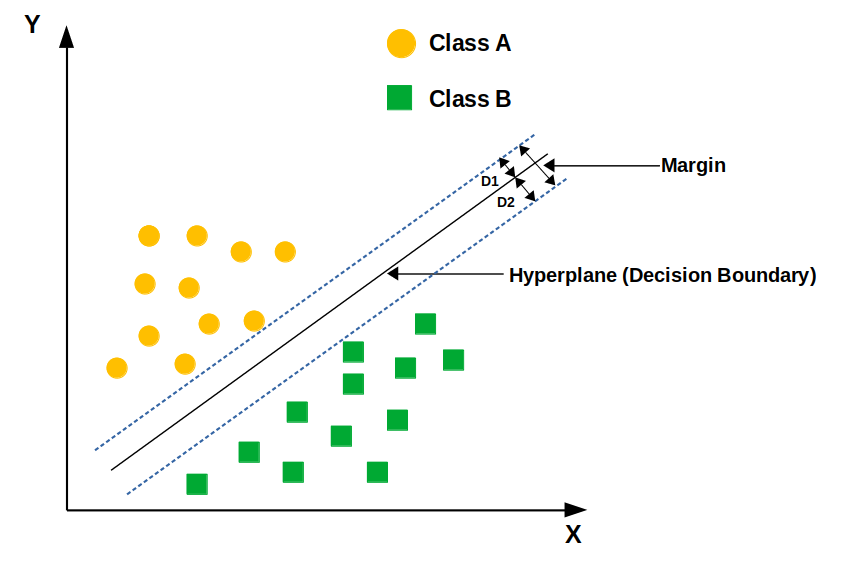

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import normalize

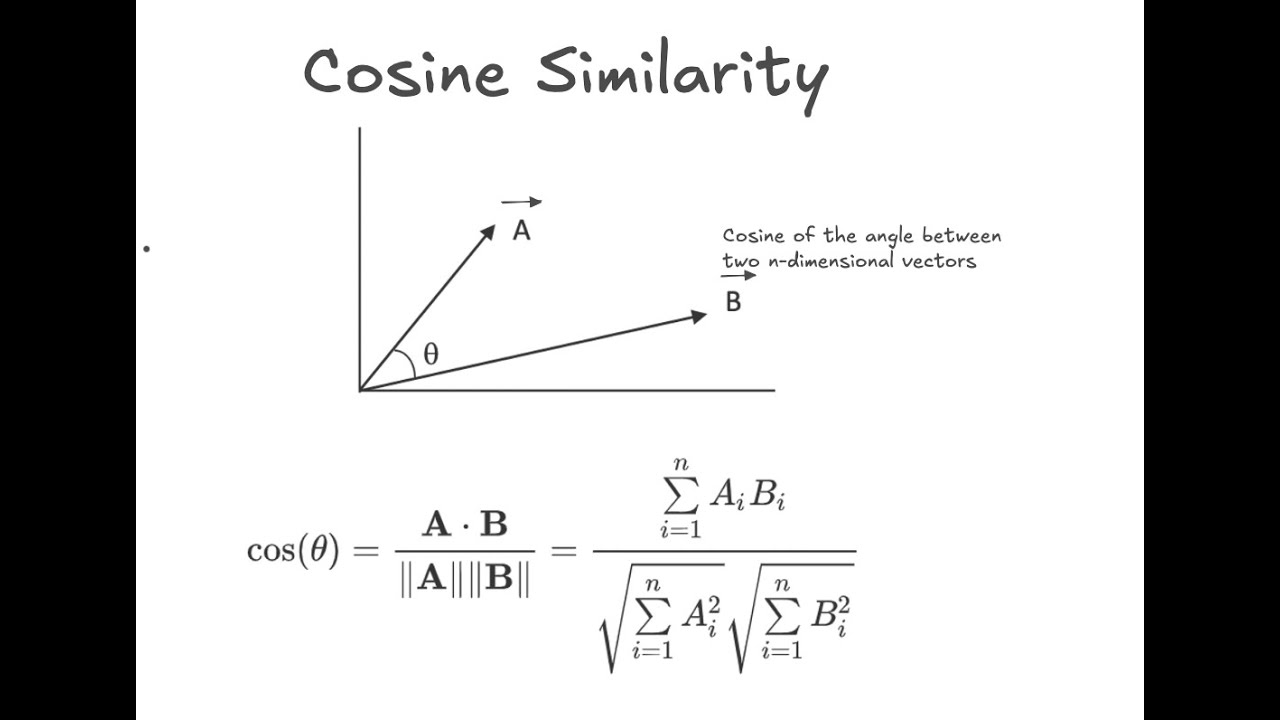

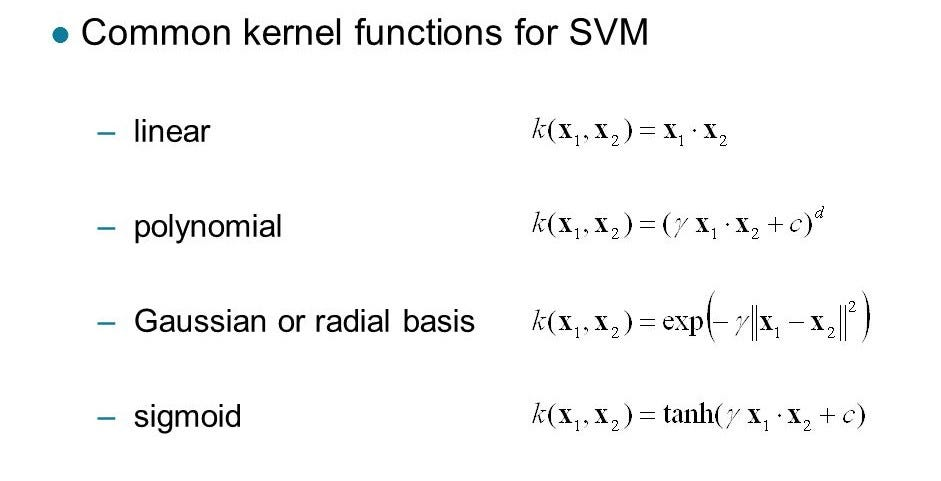

In [ ]:
X_tr_l2  = normalize(X_tr, norm='l2')
X_val_l2 = normalize(X_val, norm='l2')

In [ ]:
C_values     = [0.1, 1, 10]
gamma_values = [ 0.001, 0.01,1]

In [ ]:
svm_results = []

Linear Kernel

In [ ]:
for C in C_values:
    start = time.time()
    clf = SVC(kernel='linear', C=C)
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_val)
    acc = round(accuracy_score(y_val, y_pred), 4)
    f1 = round(f1_score(y_val, y_pred, average='weighted'), 4)
    t = round(time.time() - start, 2)
    svm_results.append({'kernel': 'linear', 'C': C, 'accuracy': acc, 'f1_score': f1, 'time': t})
    print(f"linear, C={C}, acc={acc}, f1={f1},time ={t}s")

linear, C=0.1, acc=1.0, f1=1.0,time =41.91s
linear, C=1, acc=1.0, f1=1.0,time =25.47s
linear, C=10, acc=1.0, f1=1.0,time =25.39s


Cosine kernel = Linear Kernel με μοναδιαία feautures

In [ ]:
for C in C_values:
    start = time.time()
    clf = SVC(kernel='linear', C=C)
    clf.fit(X_tr_l2, y_tr)
    y_pred = clf.predict(X_val_l2)
    acc = round(accuracy_score(y_val, y_pred), 4)
    f1 = round(f1_score(y_val, y_pred, average='weighted'), 4)
    t = round(time.time() - start, 2)
    svm_results.append({'kernel': 'cosine', 'C': C, 'accuracy': acc, 'f1_score': f1, 'time': t})
    print(f"cosine, C={C}, acc={acc}, f1={f1}, time={t}")

cosine, C=0.1, acc=0.4059, f1=0.3693, time=341.65
cosine, C=1, acc=0.8233, f1=0.824, time=179.61
cosine, C=10, acc=0.9938, f1=0.9938, time=70.91


RBF Kernel


In [ ]:
for C in C_values:
    for gamma in gamma_values:
        start = time.time()
        clf = SVC(kernel='rbf', C=C, gamma=gamma)
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_val)
        acc = accuracy_score(y_val, y_pred)
        f1  = f1_score(y_val, y_pred, average='weighted')
        t = time.time() - start
        svm_results.append({'kernel': 'rbf', 'C': C, 'gamma': gamma,
                            'accuracy': acc, 'f1_score': f1,
                            'time_sec': t})
        print(f"rbf, c={C}, gammma={gamma} acc={acc},  f1={f1},  time: {t}")

rbf, c=0.1, gammma=0.001 acc=0.30814059369877983,  f1=0.2593245214277597,  time: 421.41809916496277
rbf, c=0.1, gammma=0.01 acc=0.741759242396649,  f1=0.7407354754575503,  time: 290.34565711021423
rbf, c=0.1, gammma=1 acc=0.19650336914951738,  f1=0.2472685323671907,  time: 450.3797495365143
rbf, c=1, gammma=0.001 acc=0.7514114004735021,  f1=0.7505035929486352,  time: 267.3834614753723
rbf, c=1, gammma=0.01 acc=0.9908941904935349,  f1=0.9908857960287587,  time: 126.00953674316406
rbf, c=1, gammma=1 acc=0.970497177199053,  f1=0.9737630051143974,  time: 415.62686681747437
rbf, c=10, gammma=0.001 acc=0.9821526133673284,  f1=0.9822039633978379,  time: 122.78785490989685
rbf, c=10, gammma=0.01 acc=1.0,  f1=1.0,  time: 52.61104416847229
rbf, c=10, gammma=1 acc=0.9714077581496995,  f1=0.9745019309873776,  time: 410.42949509620667


In [ ]:
df_svm = pd.DataFrame(svm_results)

In [ ]:
print(df_svm.sort_values('accuracy', ascending=False).to_string(index=False))

kernel    C  accuracy  f1_score  time  gamma  time_sec
linear  1.0  0.976300  0.976300  1.93    NaN       NaN
linear 10.0  0.976300  0.976300  1.95    NaN       NaN
   rbf 10.0  0.960526  0.960268   NaN  0.010  3.579493
linear  0.1  0.923700  0.923300  2.40    NaN       NaN
cosine 10.0  0.846100  0.846000  3.51    NaN       NaN
   rbf 10.0  0.801316  0.801171   NaN  0.001  4.331965
   rbf  1.0  0.793421  0.792282   NaN  0.010  4.627573
   rbf 10.0  0.560526  0.675941   NaN  1.000  7.861615
   rbf  1.0  0.527632  0.646720   NaN  1.000  8.417821
cosine  1.0  0.447400  0.436100  5.28    NaN       NaN
   rbf  1.0  0.369737  0.338684   NaN  0.001  7.323507
   rbf  0.1  0.300000  0.228792   NaN  0.010  7.757809
cosine  0.1  0.076300  0.032500  6.99    NaN       NaN
   rbf  0.1  0.050000  0.011669   NaN  0.001  7.360013
   rbf  0.1  0.046053  0.004055   NaN  1.000  7.499521


In [ ]:
best_svm = df_svm.loc[df_svm['accuracy'].idxmax()]

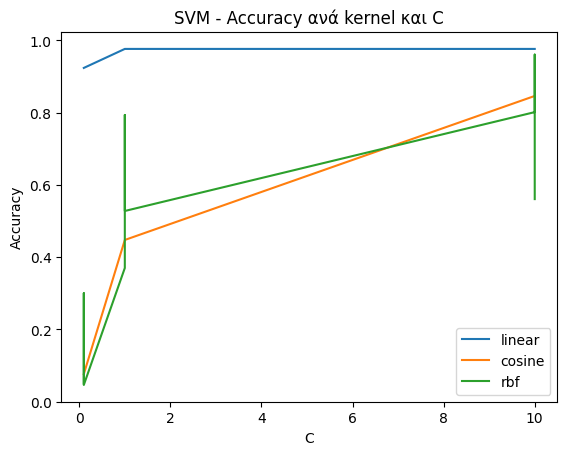

In [ ]:
for kernel in ['linear', 'cosine', 'rbf']:
    sub = df_svm[df_svm['kernel'] == kernel]
    plt.plot(sub['C'], sub['accuracy'], label=kernel)

plt.title("SVM - Accuracy ανά kernel και C")
plt.xlabel("C")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
if best_svm['kernel'] == 'rbf':
    clf_svm = SVC(kernel='rbf', C=best_svm['C'], gamma=best_svm['gamma'])
    clf_svm.fit(X_tr, y_tr)
    y_pred_svm = clf_svm.predict(X_val)
elif best_svm['kernel'] == 'cosine':
    clf_svm = SVC(kernel='linear', C=best_svm['C'])
    clf_svm.fit(X_tr_l2, y_tr)
    y_pred_svm = clf_svm.predict(X_val_l2)
else:
    clf_svm = SVC(kernel='linear', C=best_svm['C'])
    clf_svm.fit(X_tr, y_tr)
    y_pred_svm = clf_svm.predict(X_val)

pickle.dump(clf_svm, open("best_svm.pkl", "wb"))

print(classification_report(y_val, y_pred_svm,
      target_names=[LABEL_TO_LETTER[l] for l in sorted(LABEL_TO_LETTER)]))

              precision    recall  f1-score   support

           A       0.97      1.00      0.99        38
           B       1.00      1.00      1.00        25
           C       1.00      1.00      1.00        29
           D       0.95      0.98      0.96        41
           E       0.96      1.00      0.98        27
           F       0.96      1.00      0.98        47
           G       1.00      1.00      1.00        28
           H       1.00      0.93      0.96        28
           I       1.00      0.96      0.98        24
           K       1.00      0.96      0.98        26
           L       1.00      0.97      0.98        30
           M       0.96      0.92      0.94        25
           N       1.00      0.95      0.98        21
           O       1.00      1.00      1.00        27
           P       1.00      1.00      1.00        27
           Q       1.00      0.98      0.99        43
           R       0.94      0.97      0.96        35
           S       1.00    

 **Desicion Trees**

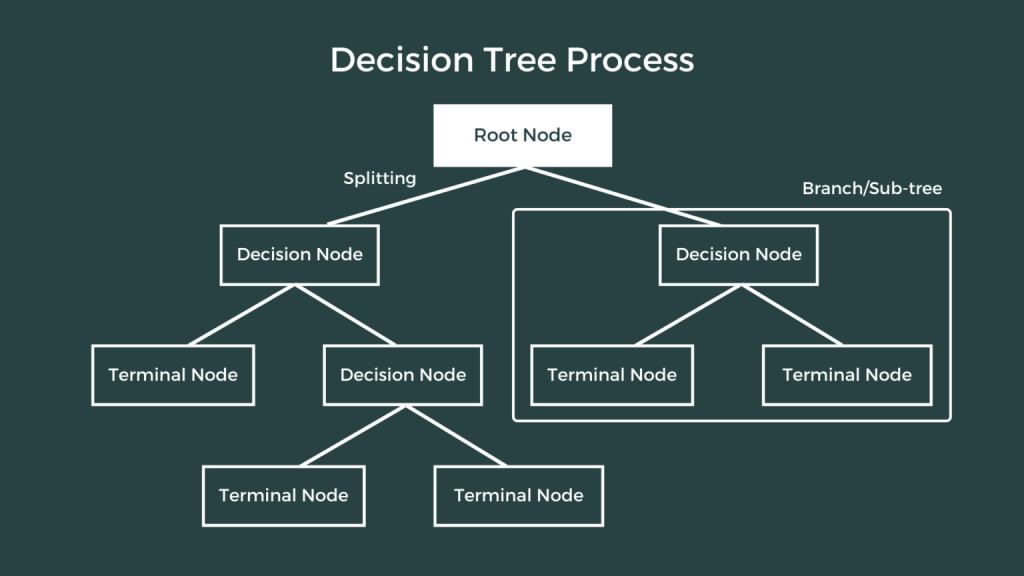

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
max_depths = [5, 10, 20]
min_samples = [1, 5, 10]
criterions = ['gini', 'entropy']

In [ ]:
dt_results = []

In [ ]:
for criterion in criterions:
    for depth in max_depths:
        for min_s in min_samples:
            start = time.time()
            clf = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=min_s, criterion=criterion)
            clf.fit(X_tr, y_tr)
            y_pred = clf.predict(X_val)
            acc = accuracy_score(y_val, y_pred)
            f1 = f1_score(y_val, y_pred, average='weighted')
            t = time.time() - start
            dt_results.append({'criterion': criterion, 'max_depth': depth, 'min_samples_leaf': min_s, 'accuracy': acc, 'f1_score': f1, 'time': t})
            print(f"criterion={criterion}, depth={depth}, min_samples={min_s}, acc={acc}, f1={f1}, time={t}s")

df_dt = pd.DataFrame(dt_results)

criterion=gini, depth=5, min_samples=1, acc=0.25263157894736843, f1=0.2357686771164898, time=1.1599533557891846s
criterion=gini, depth=5, min_samples=5, acc=0.2513157894736842, f1=0.23499108378829806, time=1.473358392715454s
criterion=gini, depth=5, min_samples=10, acc=0.2513157894736842, f1=0.2339226441235597, time=1.549440622329712s
criterion=gini, depth=10, min_samples=1, acc=0.4763157894736842, f1=0.4764470714571471, time=2.475358247756958s
criterion=gini, depth=10, min_samples=5, acc=0.4486842105263158, f1=0.4491315422767578, time=2.2390499114990234s
criterion=gini, depth=10, min_samples=10, acc=0.4368421052631579, f1=0.43974036133815203, time=2.030555486679077s
criterion=gini, depth=20, min_samples=1, acc=0.5894736842105263, f1=0.5878676394443755, time=3.194099187850952s
criterion=gini, depth=20, min_samples=5, acc=0.5197368421052632, f1=0.5160419549592297, time=3.5343339443206787s
criterion=gini, depth=20, min_samples=10, acc=0.46710526315789475, f1=0.4673441253268492, time=2.33

In [ ]:
print(df_dt.sort_values('accuracy', ascending=False).to_string(index=False))

best_dt = df_dt.loc[df_dt['accuracy'].idxmax()]
print(f"Καλύτερο: criterion={best_dt['criterion']}, depth={best_dt['max_depth']}, min_samples={best_dt['min_samples_leaf']}, acc={best_dt['accuracy']}, f1={best_dt['f1_score']}")

criterion  max_depth  min_samples_leaf  accuracy  f1_score     time
  entropy         20                 1  0.613158  0.613471 5.559605
     gini         20                 1  0.589474  0.587868 3.194099
  entropy         10                 1  0.588158  0.588433 6.153566
  entropy         20                 5  0.565789  0.568419 4.659323
  entropy         10                 5  0.538158  0.537643 4.539673
     gini         20                 5  0.519737  0.516042 3.534334
  entropy         20                10  0.502632  0.501988 5.114704
  entropy         10                10  0.492105  0.492385 4.864265
     gini         10                 1  0.476316  0.476447 2.475358
     gini         20                10  0.467105  0.467344 2.330955
     gini         10                 5  0.448684  0.449132 2.239050
     gini         10                10  0.436842  0.439740 2.030555
  entropy          5                 5  0.298684  0.265442 2.437730
  entropy          5                 1  0.298684

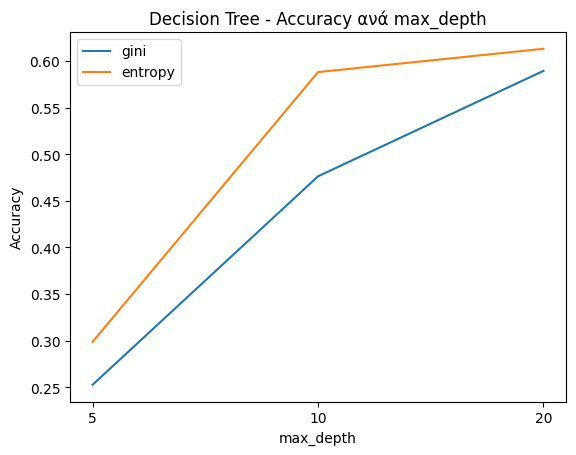

In [ ]:
for criterion in ['gini', 'entropy']:
    sub = df_dt[(df_dt['criterion'] == criterion) & (df_dt['min_samples_leaf'] == 1)]
    plt.plot([str(d) for d in sub['max_depth']], sub['accuracy'], label=criterion)

plt.title("Decision Tree - Accuracy ανά max_depth")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
clf_dt = DecisionTreeClassifier(criterion=best_dt['criterion'], max_depth=best_dt['max_depth'], min_samples_leaf=int(best_dt['min_samples_leaf']), random_state=42)
clf_dt.fit(X_tr, y_tr)

pickle.dump(clf_dt, open("best_dt.pkl", "wb"))

print(classification_report(y_val, clf_dt.predict(X_val),
      target_names=[LABEL_TO_LETTER[l] for l in sorted(LABEL_TO_LETTER)]))

              precision    recall  f1-score   support

           A       0.85      0.76      0.81        38
           B       0.64      0.64      0.64        25
           C       0.71      0.76      0.73        29
           D       0.79      0.63      0.70        41
           E       0.59      0.63      0.61        27
           F       0.77      0.51      0.62        47
           G       0.63      0.93      0.75        28
           H       0.52      0.46      0.49        28
           I       0.36      0.54      0.43        24
           K       0.64      0.54      0.58        26
           L       0.52      0.50      0.51        30
           M       0.57      0.64      0.60        25
           N       0.67      0.67      0.67        21
           O       0.65      0.74      0.69        27
           P       0.66      0.78      0.71        27
           Q       0.77      0.79      0.78        43
           R       0.56      0.63      0.59        35
           S       0.65    

**Random Forest**

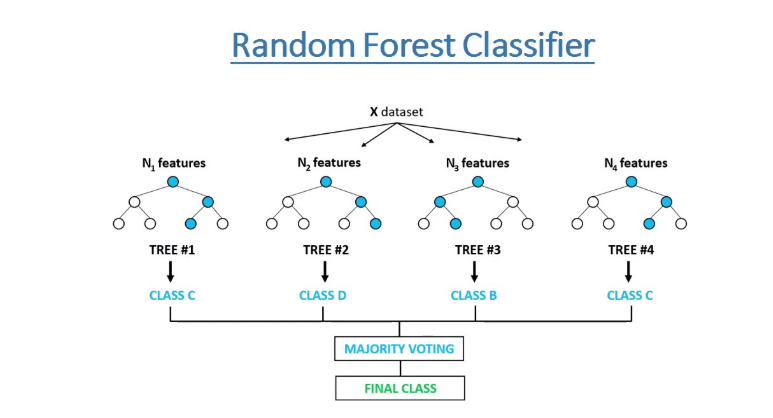

In [ ]:
from sklearn.ensemble import RandomForestClassifier

Στην μεταβλητή n_estimators αναθέτουμε των αριθμών των δέντρων. Συγκεκριμένα επιλέγοθνται οι τιμές 10 (λίγα δέντρα), 50 (σχετικά λίγα δέντρα) και 100 (η deafault τιμή που δίνει η scikit) Πηγή https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

In [ ]:
n_estimators_list = [10, 50, 100]
max_depths_rf = [5, 10, 20]

In [ ]:
rf_results = []

In [ ]:
for n_est in n_estimators_list:
    for depth in max_depths_rf:
        start = time.time()
        clf = RandomForestClassifier(n_estimators=n_est, max_depth=depth, random_state=42)
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_val)
        acc = accuracy_score(y_val, y_pred)
        f1 = f1_score(y_val, y_pred, average='weighted')
        t = time.time() - start
        rf_results.append({'n_estimators': n_est, 'max_depth': depth, 'accuracy': acc, 'f1_score': f1, 'time': t})
        print(f"n_estimators={n_est}, depth={depth}, acc={acc}, f1={f1}, time={t}s")

df_rf = pd.DataFrame(rf_results)

n_estimators=10, depth=5, acc=0.4144736842105263, f1=0.37985443520325135, time=0.3295176029205322s
n_estimators=10, depth=10, acc=0.7394736842105263, f1=0.7403987908601235, time=0.7007498741149902s
n_estimators=10, depth=20, acc=0.7868421052631579, f1=0.7858942074993841, time=0.8949449062347412s
n_estimators=50, depth=5, acc=0.5236842105263158, f1=0.4958734121277822, time=2.023740291595459s
n_estimators=50, depth=10, acc=0.8302631578947368, f1=0.8292305484549333, time=3.8555896282196045s
n_estimators=50, depth=20, acc=0.8644736842105263, f1=0.8638717166689173, time=4.369468927383423s
n_estimators=100, depth=5, acc=0.5355263157894737, f1=0.5041016494155796, time=3.1785452365875244s
n_estimators=100, depth=10, acc=0.8486842105263158, f1=0.8487706669383671, time=7.687452793121338s
n_estimators=100, depth=20, acc=0.8828947368421053, f1=0.8829404221073063, time=9.633418560028076s


In [ ]:
print(df_rf.sort_values('accuracy', ascending=False).to_string(index=False))

best_rf = df_rf.loc[df_rf['accuracy'].idxmax()]
print(f"Καλύτερο: n_estimators={best_rf['n_estimators']}, depth={best_rf['max_depth']}, acc={best_rf['accuracy']}, f1={best_rf['f1_score']}")

 n_estimators  max_depth  accuracy  f1_score     time
          100         20  0.882895  0.882940 9.633419
           50         20  0.864474  0.863872 4.369469
          100         10  0.848684  0.848771 7.687453
           50         10  0.830263  0.829231 3.855590
           10         20  0.786842  0.785894 0.894945
           10         10  0.739474  0.740399 0.700750
          100          5  0.535526  0.504102 3.178545
           50          5  0.523684  0.495873 2.023740
           10          5  0.414474  0.379854 0.329518
Καλύτερο: n_estimators=100.0, depth=20.0, acc=0.8828947368421053, f1=0.8829404221073063


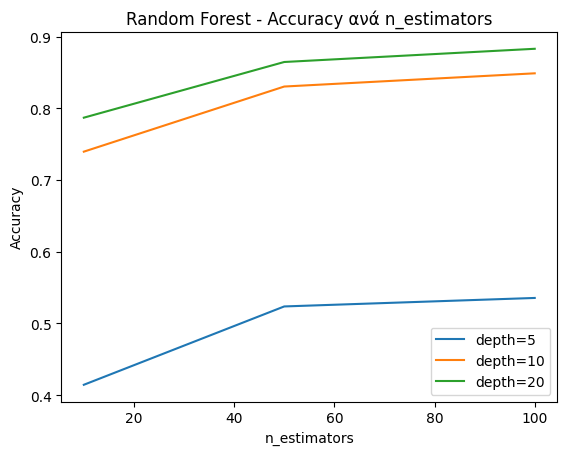

In [ ]:
for depth in max_depths_rf:
    sub = df_rf[df_rf['max_depth'] == depth]
    plt.plot(sub['n_estimators'], sub['accuracy'], label=f"depth={depth}")

plt.title("Random Forest - Accuracy ανά n_estimators")
plt.xlabel("n_estimators")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Καλύτερο Μοντέλο

In [ ]:
clf_rf = RandomForestClassifier(n_estimators=int(best_rf['n_estimators']), max_depth=int(best_rf['max_depth']), random_state=42)
clf_rf.fit(X_tr, y_tr)

pickle.dump(clf_rf, open("best_rf.pkl", "wb"))

print(classification_report(y_val, clf_rf.predict(X_val),
      target_names=[LABEL_TO_LETTER[l] for l in sorted(LABEL_TO_LETTER)]))

              precision    recall  f1-score   support

           A       0.97      0.84      0.90        38
           B       0.91      0.84      0.88        25
           C       0.96      0.93      0.95        29
           D       0.97      0.78      0.86        41
           E       0.76      0.96      0.85        27
           F       0.92      0.98      0.95        47
           G       0.96      0.96      0.96        28
           H       0.90      0.93      0.91        28
           I       0.88      0.92      0.90        24
           K       0.81      0.81      0.81        26
           L       1.00      0.90      0.95        30
           M       0.77      0.80      0.78        25
           N       0.85      0.81      0.83        21
           O       0.89      0.93      0.91        27
           P       0.84      0.96      0.90        27
           Q       0.91      0.98      0.94        43
           R       0.77      0.94      0.85        35
           S       0.83    

**ADABOOST**


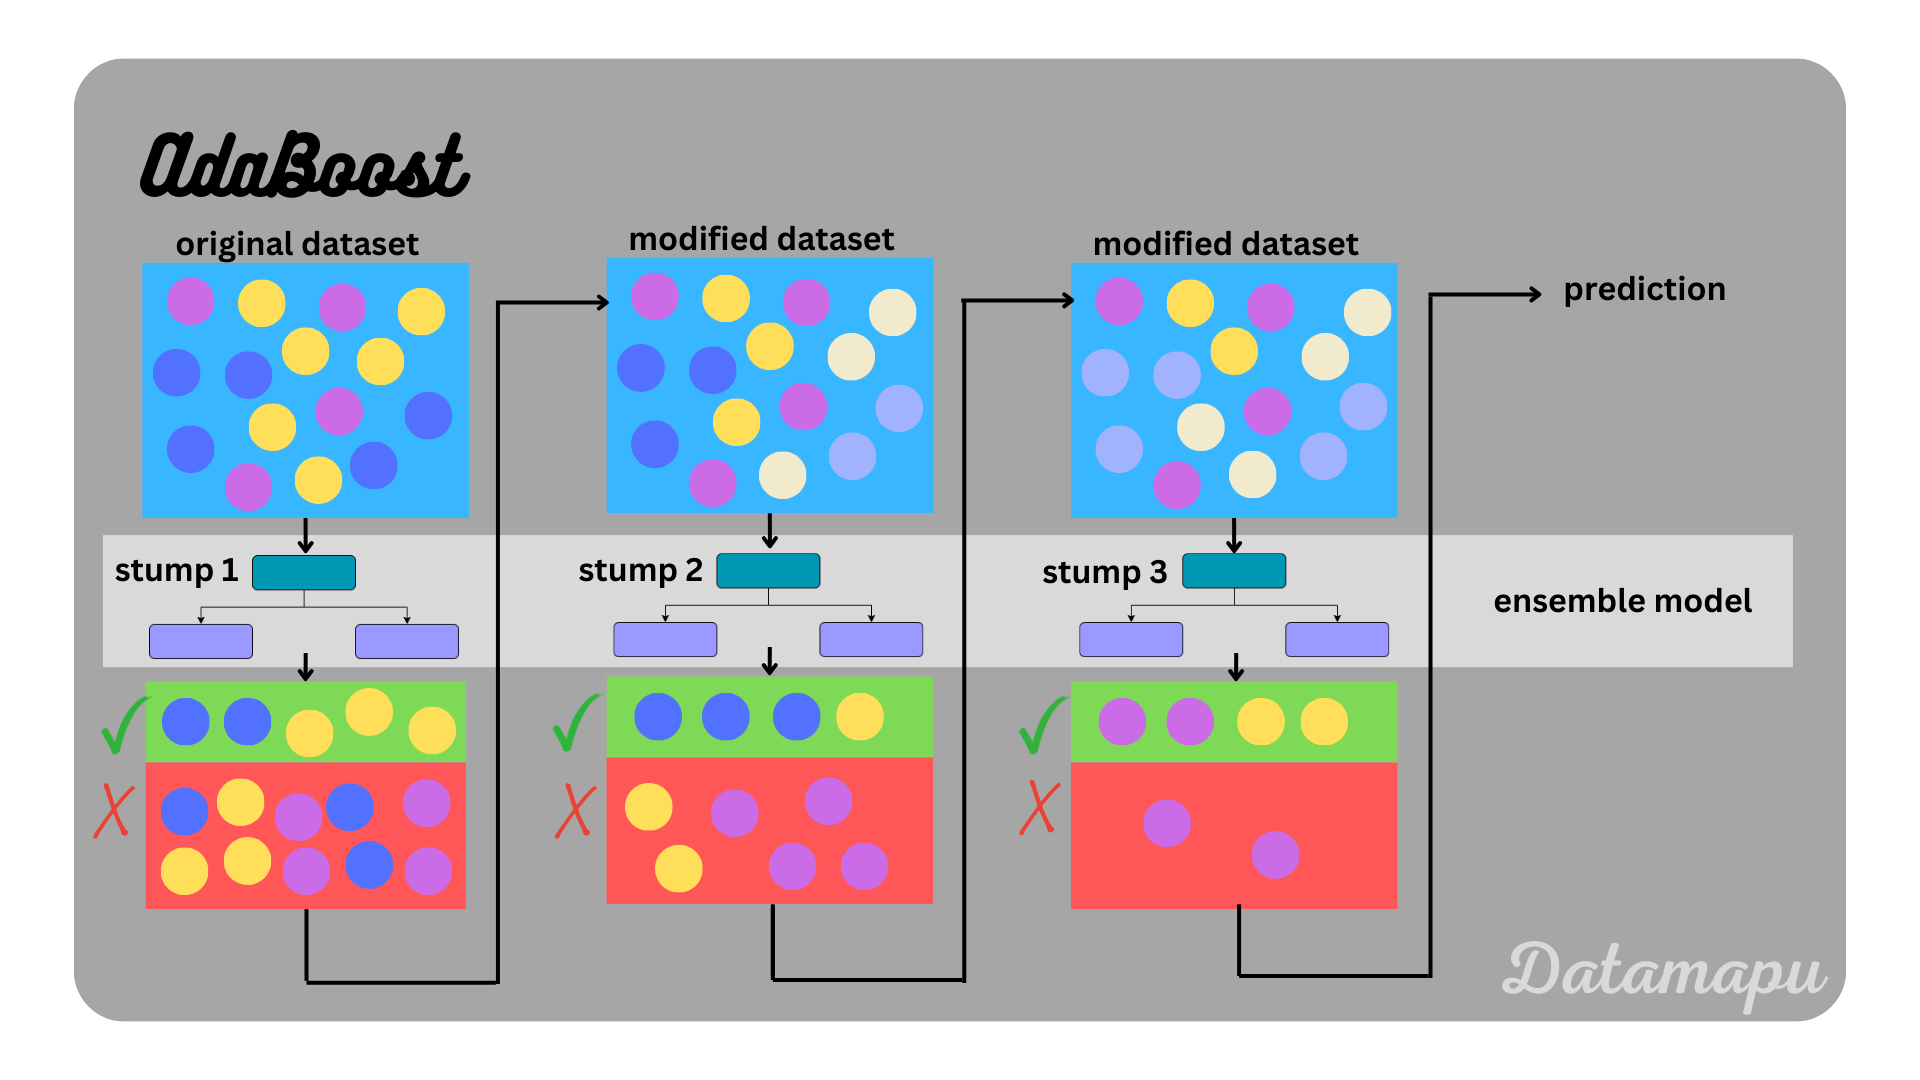

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

In [ ]:
n_estimators_list = [50, 100, 200]
learning_rates = [0.1, 0.5, 1.0]

In [ ]:
ada_results = []

In [ ]:
for n_est in n_estimators_list:
    for lr in learning_rates:
        start = time.time()
        clf = AdaBoostClassifier(n_estimators=n_est, learning_rate=lr, random_state=42)
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_val)
        acc = accuracy_score(y_val, y_pred)
        f1 = f1_score(y_val, y_pred, average='weighted')
        t = time.time() - start
        ada_results.append({'n_estimators': n_est, 'learning_rate': lr, 'accuracy': acc, 'f1_score': f1, 'time': t})
        print(f"n_estimators={n_est}, lr={lr}, acc={acc}, f1={f1}, time={t}s")

df_ada = pd.DataFrame(ada_results)

n_estimators=50, lr=0.1, acc=0.10657894736842105, f1=0.05616400531649755, time=10.15418553352356s
n_estimators=50, lr=0.5, acc=0.1723684210526316, f1=0.10906732959441086, time=10.212667465209961s
n_estimators=50, lr=1.0, acc=0.19605263157894737, f1=0.15818221123697562, time=10.278551816940308s
n_estimators=100, lr=0.1, acc=0.15526315789473685, f1=0.07304088471355258, time=20.15793490409851s
n_estimators=100, lr=0.5, acc=0.25526315789473686, f1=0.22495347642729038, time=20.68523335456848s
n_estimators=100, lr=1.0, acc=0.2381578947368421, f1=0.22400543682518084, time=19.94249439239502s
n_estimators=200, lr=0.1, acc=0.16578947368421051, f1=0.11741688324970058, time=41.80959439277649s
n_estimators=200, lr=0.5, acc=0.3026315789473684, f1=0.3103325208182519, time=41.03099513053894s
n_estimators=200, lr=1.0, acc=0.2986842105263158, f1=0.29984346983302357, time=40.267977237701416s


In [ ]:
print(df_ada.sort_values('accuracy', ascending=False).to_string(index=False))

best_row_ada = df_ada.loc[df_ada['accuracy'].idxmax()]
print(f"\nΚαλύτερο AdaBoost:")
print(f"n_estimators={best_row_ada['n_estimators']}, learning_rate={best_row_ada['learning_rate']}")
print(f"Accuracy: {best_row_ada['accuracy']}, F1: {best_row_ada['f1_score']}")

 n_estimators  learning_rate  accuracy  f1_score      time
          200            0.5  0.302632  0.310333 41.030995
          200            1.0  0.298684  0.299843 40.267977
          100            0.5  0.255263  0.224953 20.685233
          100            1.0  0.238158  0.224005 19.942494
           50            1.0  0.196053  0.158182 10.278552
           50            0.5  0.172368  0.109067 10.212667
          200            0.1  0.165789  0.117417 41.809594
          100            0.1  0.155263  0.073041 20.157935
           50            0.1  0.106579  0.056164 10.154186

Καλύτερο AdaBoost:
n_estimators=200.0, learning_rate=0.5
Accuracy: 0.3026315789473684, F1: 0.3103325208182519


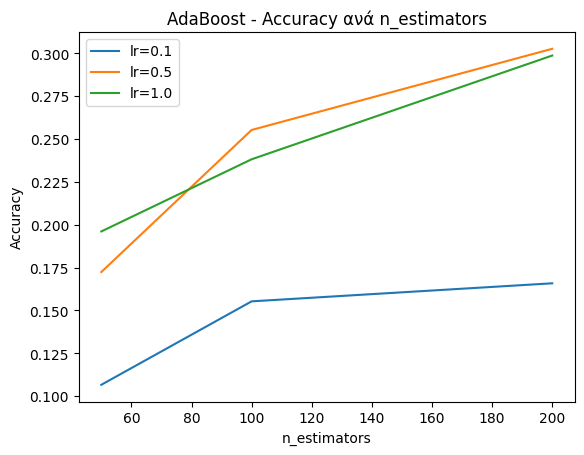

In [ ]:
for lr in learning_rates:
    sub = df_ada[df_ada['learning_rate'] == lr]
    plt.plot(sub['n_estimators'], sub['accuracy'], label=f"lr={lr}")

plt.title("AdaBoost - Accuracy ανά n_estimators")
plt.xlabel("n_estimators")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
best_ada = AdaBoostClassifier(
    n_estimators=int(best_row_ada['n_estimators']),
    learning_rate=float(best_row_ada['learning_rate']),
)
best_ada.fit(X_tr, y_tr)

with open("best_ada.pkl", "wb") as f:
    pickle.dump(best_ada, f)

print("Αποθηκεύτηκε το best_ada.pkl")
print(classification_report(y_val, best_ada.predict(X_val),
      target_names=[LABEL_TO_LETTER[l] for l in sorted(LABEL_TO_LETTER)]))

Αποθηκεύτηκε το best_ada.pkl
              precision    recall  f1-score   support

           A       0.60      0.24      0.34        38
           B       0.67      0.32      0.43        25
           C       0.73      0.38      0.50        29
           D       0.29      0.29      0.29        41
           E       0.56      0.33      0.42        27
           F       0.45      0.28      0.34        47
           G       0.54      0.25      0.34        28
           H       0.31      0.36      0.33        28
           I       0.13      0.17      0.15        24
           K       0.33      0.19      0.24        26
           L       0.28      0.50      0.36        30
           M       0.06      0.12      0.08        25
           N       0.11      0.14      0.12        21
           O       0.38      0.74      0.50        27
           P       0.24      0.74      0.36        27
           Q       0.55      0.26      0.35        43
           R       0.10      0.26      0.14        3

**FNN**

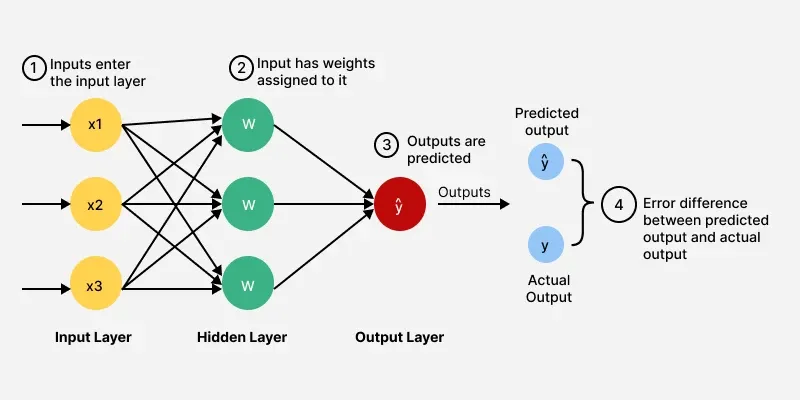

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

In [ ]:
fnn_configs = [
    {'hidden layer': (128,), 'name': 'FNN_1layer'},
    {'hidden layer': (128, 128), 'name': 'FNN_2layers'},
    {'hidden layer': (128, 128, 128), 'name': 'FNN_3layers'},
]

In [ ]:
fnn_results = []

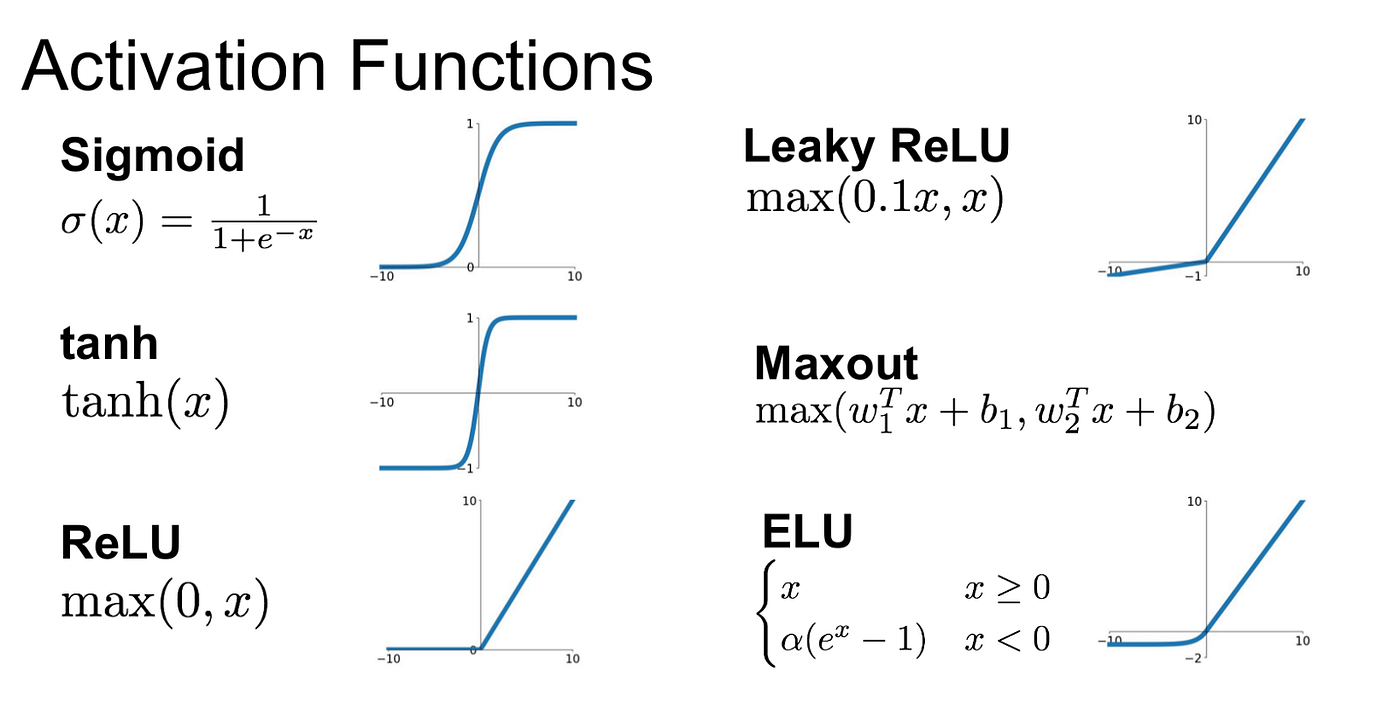

In [ ]:
for config in fnn_configs:
    start = time.time()
    clf = MLPClassifier(hidden_layer_sizes=config['hidden layer'], activation='relu', max_iter=50)
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='weighted')
    t = time.time() - start
    fnn_results.append({'model': config['name'], 'layers': str(config['hidden layer']), 'accuracy': acc, 'f1_score': f1, 'time': t})
    print(f"{config['name']}, acc={acc}, f1={f1}, time={t}")

df_fnn = pd.DataFrame(fnn_results)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


FNN_1layer, acc=0.718421052631579, f1=0.7158725958942452, time=3.5970098972320557


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


FNN_2layers, acc=0.7342105263157894, f1=0.7373188004339657, time=7.2798967361450195
FNN_3layers, acc=0.7776315789473685, f1=0.7755719510960205, time=5.387997627258301


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
print(df_fnn.to_string(index=False))

best_fnn = df_fnn.loc[df_fnn['accuracy'].idxmax()]
print(f"Καλύτερο: {best_fnn['model']}, acc={best_fnn['accuracy']}, f1={best_fnn['f1_score']}, time={best_fnn['time']}s")

      model          layers  accuracy  f1_score     time
 FNN_1layer          (128,)  0.718421  0.715873 3.597010
FNN_2layers      (128, 128)  0.734211  0.737319 7.279897
FNN_3layers (128, 128, 128)  0.777632  0.775572 5.387998
Καλύτερο: FNN_3layers, acc=0.7776315789473685, f1=0.7755719510960205, time=5.387997627258301s


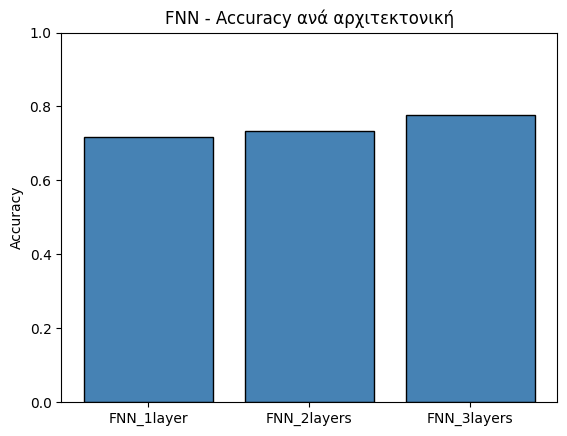

In [ ]:
plt.bar(df_fnn['model'], df_fnn['accuracy'], color='steelblue', edgecolor='black')
plt.title("FNN - Accuracy ανά αρχιτεκτονική")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

In [ ]:
best_fnn = MLPClassifier(
    hidden_layer_sizes=eval(best_fnn['layers']),
    activation='relu',
    max_iter=50,
)
best_fnn.fit(X_tr, y_tr)

with open("best_fnn.pkl", "wb") as f:
    pickle.dump(best_fnn, f)

print("Αποθηκεύτηκε το best_fnn.pkl")
print(classification_report(y_val, best_fnn.predict(X_val),
      target_names=[LABEL_TO_LETTER[l] for l in sorted(LABEL_TO_LETTER)]))

Αποθηκεύτηκε το best_fnn.pkl
              precision    recall  f1-score   support

           A       0.86      0.82      0.84        38
           B       0.81      1.00      0.89        25
           C       0.93      0.93      0.93        29
           D       0.96      0.61      0.75        41
           E       0.78      0.93      0.85        27
           F       0.98      0.85      0.91        47
           G       0.87      0.93      0.90        28
           H       0.96      0.79      0.86        28
           I       0.75      0.88      0.81        24
           K       0.73      0.85      0.79        26
           L       0.68      0.93      0.79        30
           M       0.75      0.72      0.73        25
           N       0.76      0.62      0.68        21
           O       0.93      0.93      0.93        27
           P       1.00      0.93      0.96        27
           Q       0.98      0.93      0.95        43
           R       0.89      0.71      0.79        3

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


**CNN**

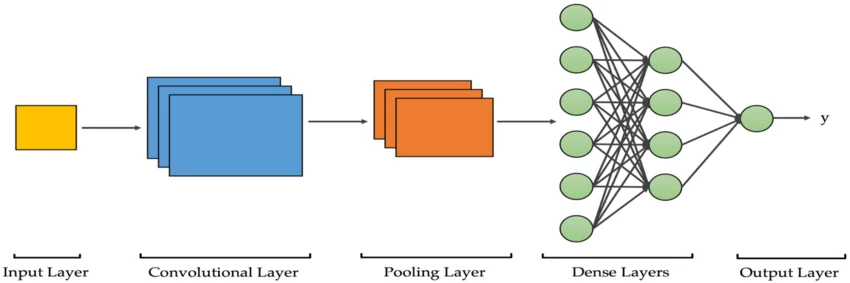

Για να μπορέσουμε να κατασκευάσουμε conolutional neural network πρέπει να χρησιμοποιήσουμε την βιβλιοθήκη keras

In [ ]:
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import LabelEncoder

In [ ]:
le = LabelEncoder()
y_tr_enc  = le.fit_transform(y_tr)
y_val_enc = le.transform(y_val)

In [ ]:
cnn_configs = [
    {'Kernels': 32, 'kernel_size': 3, 'name': 'CNN_32f_3k'},
    {'Kernels': 64, 'kernel_size': 3, 'name': 'CNN_64f_3k'},
    {'Kernels': 64, 'kernel_size': 5, 'name': 'CNN_64f_5k'},
]

In [ ]:
X_tr_cnn  = X_tr.reshape(-1, 28, 28, 1)
X_val_cnn = X_val.reshape(-1, 28, 28, 1)
n_classes = len(LABEL_TO_LETTER)

In [ ]:
cnn_results = []

In [ ]:
for config in cnn_configs:
    start = time.time()
    model = keras.Sequential([
        keras.layers.Conv2D(config['Kernels'], config['kernel_size'], activation='relu', input_shape=(28, 28, 1)),
        keras.layers.MaxPooling2D(2, 2),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model.fit(X_tr_cnn, y_tr_enc, epochs=10, batch_size=32, verbose=0)
    y_pred = le.inverse_transform(model.predict(X_val_cnn, verbose=0).argmax(axis=1))
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='weighted')
    t = time.time() - start
    cnn_results.append({'model': config['name'], 'filters': config['Kernels'], 'kernel_size': config['kernel_size'], 'accuracy': acc, 'f1_score': f1, 'time': t})
    print(f"{config['name']},kernels ={config['Kernels']},kernel size ={config['kernel_size']}, acc={acc}, f1={f1}, time={t}s")

df_cnn = pd.DataFrame(cnn_results)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN_32f_3k,kernels =32,kernel size =3, acc=0.9263157894736842, f1=0.9258566119863866, time=28.128008365631104s


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN_64f_3k,kernels =64,kernel size =3, acc=0.9605263157894737, f1=0.9605204119150723, time=41.820072412490845s


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN_64f_5k,kernels =64,kernel size =5, acc=0.9763157894736842, f1=0.976383022866212, time=38.74967622756958s


In [ ]:
print(df_cnn.to_string(index=False))

best_row_cnn = df_cnn.loc[df_cnn['accuracy'].idxmax()]
print(f"\nΚαλύτερο CNN: {best_row_cnn['model']}")
print(f"Accuracy: {best_row_cnn['accuracy']}, F1: {best_row_cnn['f1_score']}")

     model  filters  kernel_size  accuracy  f1_score      time
CNN_32f_3k       32            3  0.926316  0.925857 28.128008
CNN_64f_3k       64            3  0.960526  0.960520 41.820072
CNN_64f_5k       64            5  0.976316  0.976383 38.749676

Καλύτερο CNN: CNN_64f_5k
Accuracy: 0.9763157894736842, F1: 0.976383022866212


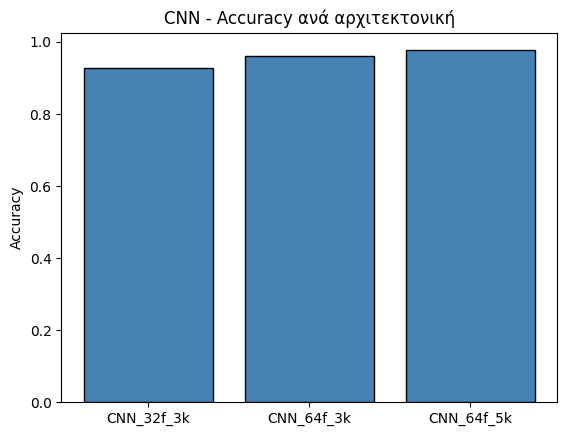

In [ ]:
plt.bar(df_cnn['model'], df_cnn['accuracy'], color='steelblue', edgecolor='black')
plt.title("CNN - Accuracy ανά αρχιτεκτονική")
plt.ylabel("Accuracy")
plt.show()

#**[C] Σύγκριση όλων των μοντέλων και επιλογη καλύτερου**

In [ ]:
best_knn = df_knn.loc[df_knn['accuracy'].idxmax()]
best_svm = df_svm.loc[df_svm['accuracy'].idxmax()]
best_dt = df_dt.loc[df_dt['accuracy'].idxmax()]
best_rf = df_rf.loc[df_rf['accuracy'].idxmax()]
best_row_ada = df_ada.loc[df_ada['accuracy'].idxmax()]
best_fnn = df_fnn.loc[df_fnn['accuracy'].idxmax()]
best_row_cnn = df_cnn.loc[df_cnn['accuracy'].idxmax()]

all_results = [
    {'model': 'kNN','accuracy': best_knn['accuracy'],'f1_score': best_knn['f1_score']},
    {'model': 'SVM', 'accuracy': best_svm['accuracy'], 'f1_score': best_svm['f1_score']},
    {'model': 'Decision Tree','accuracy': best_dt['accuracy'],  'f1_score': best_dt['f1_score']},
    {'model': 'Random Forest','accuracy': best_rf['accuracy'],  'f1_score': best_rf['f1_score']},
    {'model': 'AdaBoost', 'accuracy': best_row_ada['accuracy'], 'f1_score': best_row_ada['f1_score']},
    {'model': 'FNN', 'accuracy': best_fnn['accuracy'], 'f1_score': best_fnn['f1_score']},
    {'model': 'CNN', 'accuracy': best_row_cnn['accuracy'], 'f1_score': best_row_cnn['f1_score']},
]

df_all = pd.DataFrame(all_results).sort_values('accuracy', ascending=False)
print(df_all.to_string(index=False))

        model  accuracy  f1_score
          CNN  0.976316  0.976383
          SVM  0.976300  0.976300
          kNN  0.972368  0.972441
Random Forest  0.882895  0.882940
          FNN  0.777632  0.775572
Decision Tree  0.613158  0.613471
     AdaBoost  0.302632  0.310333


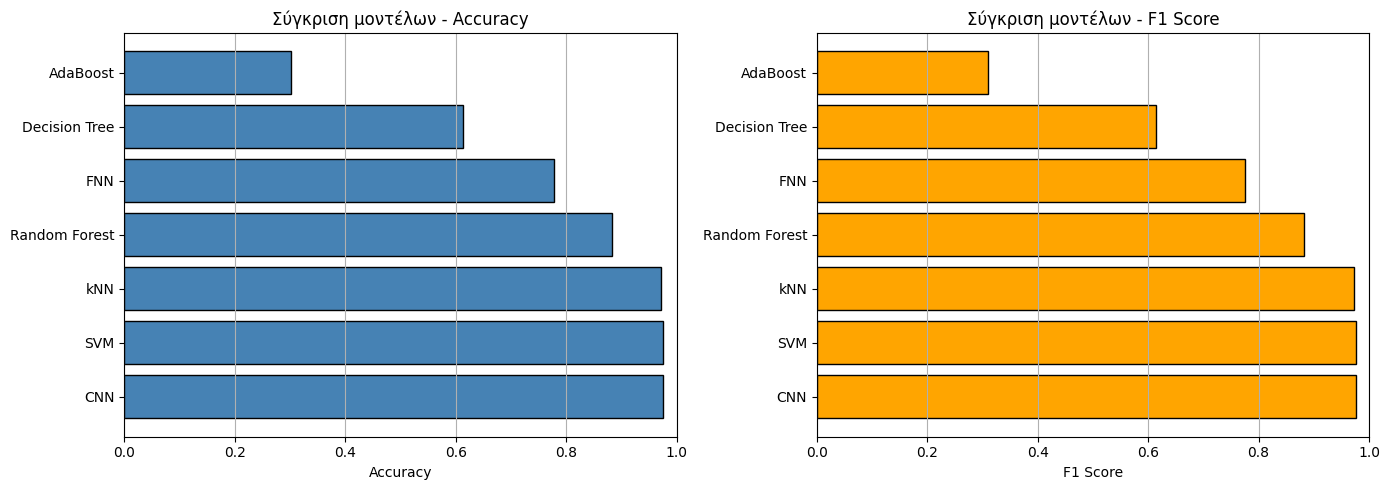

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(df_all['model'], df_all['accuracy'], color='steelblue', edgecolor='black')
axes[0].set_title("Σύγκριση μοντέλων - Accuracy")
axes[0].set_xlabel("Accuracy")
axes[0].set_xlim(0, 1)
axes[0].grid(True, axis='x')

axes[1].barh(df_all['model'], df_all['f1_score'], color='orange', edgecolor='black')
axes[1].set_title("Σύγκριση μοντέλων - F1 Score")
axes[1].set_xlabel("F1 Score")
axes[1].set_xlim(0, 1)
axes[1].grid(True, axis='x')

plt.tight_layout()
plt.show()

In [ ]:
df_candidates = df_all[df_all['model'] != 'CNN'].copy()
best_model_row = df_candidates.loc[df_candidates['accuracy'].idxmax()]
print(f"Καλύτερο μοντέλο: {best_model_row['model']}")
print(f"Accuracy: {best_model_row['accuracy']}")
print(f"F1 Score: {best_model_row['f1_score']}")

Καλύτερο μοντέλο: SVM
Accuracy: 0.9763
F1 Score: 0.9763


In [ ]:

model_files = {
    'kNN':           'best_knn.pkl',
    'SVM':           'best_svm.pkl',
    'Decision Tree': 'best_dt.pkl',
    'Random Forest': 'best_rf.pkl',
    'AdaBoost':      'best_ada.pkl',
    'FNN':           'best_fnn.pkl',
}

with open(model_files[best_model_row['model']], 'rb') as f:
    best_model = pickle.load(f)


with open("best_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

print(f"Αποθηκεύτηκε το best_model.pkl ({best_model_row['model']})")

Αποθηκεύτηκε το best_model.pkl (SVM)
